# How reliable is a 9-out-of-10 mastery gate?

A student advances if they answer at least 9 of 10 unaided questions correctly (a 90% bar).
This notebook asks: for a student whose *true* accuracy is p, how often does the gate pass them? And what changes if the bar is lowered to 8/10 or 7/10?

**Assumption:** the 10 questions are independent and of similar difficulty for that student. Real assessments vary in item difficulty, so treat these numbers as a first-order estimate, not a measurement of any specific product.

In [1]:
import numpy as np
from scipy.stats import binom
import matplotlib.pyplot as plt

def gate_pass(p, n=10, k=9):
    return 1 - binom.cdf(k - 1, n, p)

for p in [0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]:
    print(f"true accuracy {p:.2f}: passes {gate_pass(p):.1%} of the time")

true accuracy 0.60: passes 4.6% of the time
true accuracy 0.70: passes 14.9% of the time
true accuracy 0.75: passes 24.4% of the time
true accuracy 0.80: passes 37.6% of the time
true accuracy 0.85: passes 54.4% of the time
true accuracy 0.90: passes 73.6% of the time
true accuracy 0.95: passes 91.4% of the time


**What this shows**
- A student who really answers 90% correctly **fails the gate about 26% of the time** (1 in 4).
- A student at 75% accuracy **passes about 24% of the time**.
- Ten questions can't reliably tell a 75% student from a 90% student. This is a sample-size limit, not a question-quality problem.

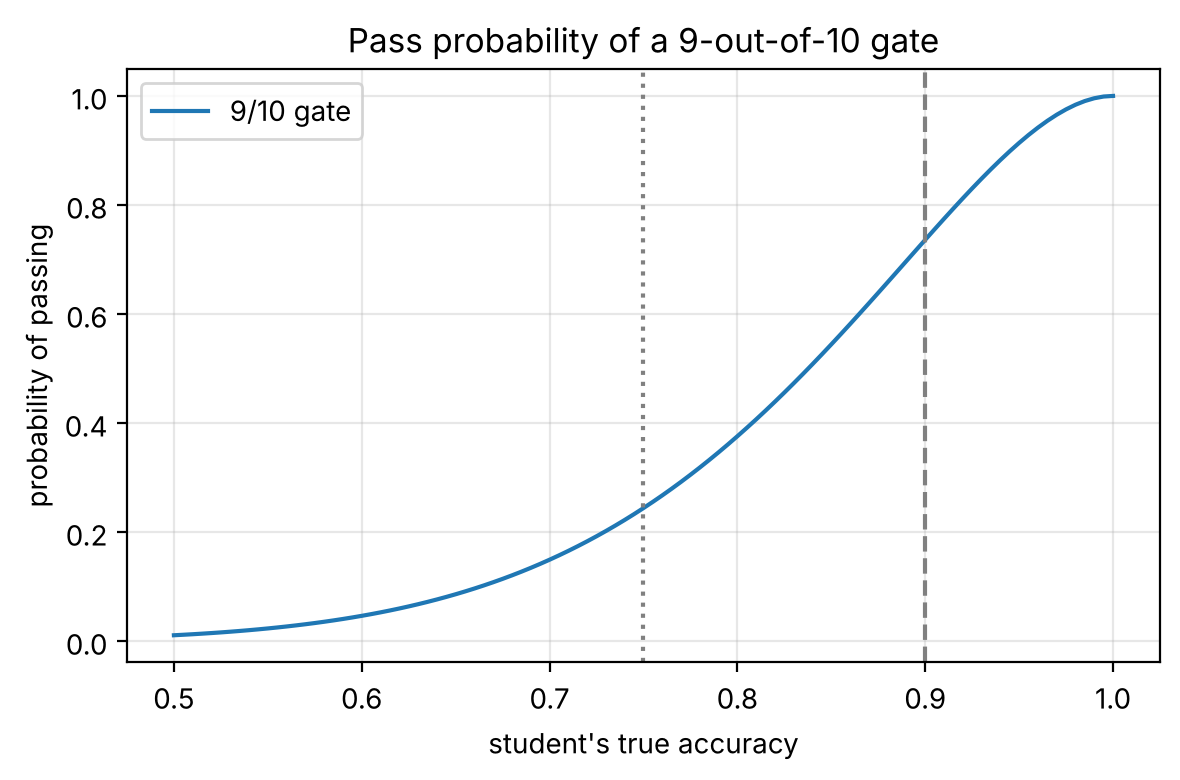

In [2]:
ps = np.linspace(0.5, 1.0, 101)
plt.figure(figsize=(6, 4))
plt.plot(ps, [gate_pass(p) for p in ps], label="9/10 gate")
plt.axvline(0.9, ls="--", c="gray"); plt.axvline(0.75, ls=":", c="gray")
plt.xlabel("student's true accuracy"); plt.ylabel("probability of passing")
plt.title("Pass probability of a 9-out-of-10 gate")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

## Cheap improvement: extend only the borderline cases

Rule: 10/10 passes immediately, 7 or fewer fails immediately. Students at 8 or 9 get 5 more questions and pass if they reach 13 of 15.

In [3]:
def extended_rule(p):
    pass_p = binom.pmf(10, 10, p)
    for k in (8, 9):
        need = 13 - k
        pass_p += binom.pmf(k, 10, p) * (1 - binom.cdf(need - 1, 5, p))
    avg_q = 10 + 5 * (binom.pmf(8, 10, p) + binom.pmf(9, 10, p))
    return pass_p, avg_q

print("true acc | 9/10 gate | extended rule | avg questions")
for p in [0.7, 0.75, 0.8, 0.85, 0.9, 0.95]:
    r, q = extended_rule(p)
    print(f"  {p:.2f}   |   {gate_pass(p):.1%}   |    {r:.1%}     |   {q:.1f}")

true acc | 9/10 gate | extended rule | avg questions
  0.70   |   14.9%   |    13.1%     |   11.8
  0.75   |   24.4%   |    24.2%     |   12.3
  0.80   |   37.6%   |    40.4%     |   12.9
  0.85   |   54.4%   |    60.9%     |   13.1
  0.90   |   73.6%   |    81.9%     |   12.9
  0.95   |   91.4%   |    96.4%     |   11.9


**Result:** false fails for a true-90% student drop from about 26% to about 18%, with ~13 questions on average instead of 10. False passes at 75% barely move.

## What lowering the bar does

Lowering the threshold trades false fails for false passes:

In [4]:
print("true acc |  9/10  |  8/10  |  7/10")
for p in [0.7, 0.75, 0.8, 0.85, 0.9, 0.95]:
    row = [gate_pass(p, k=k) for k in (9, 8, 7)]
    print(f"  {p:.2f}   | " + " | ".join(f"{r:5.1%}" for r in row))

true acc |  9/10  |  8/10  |  7/10
  0.70   | 14.9% | 38.3% | 65.0%
  0.75   | 24.4% | 52.6% | 77.6%
  0.80   | 37.6% | 67.8% | 87.9%
  0.85   | 54.4% | 82.0% | 95.0%
  0.90   | 73.6% | 93.0% | 98.7%
  0.95   | 91.4% | 98.8% | 99.9%


- At **8/10**, a true-90% student fails only ~7% of the time, but a 75% student passes ~53% of the time.
- No single threshold on 10 questions gets both errors low. Ten answers just don't carry enough information.

## A better option: treat Summit as evidence, not a standalone test

If the platform already keeps a per-skill mastery estimate (e.g. from Bayesian Knowledge Tracing during practice), Summit doesn't have to be a separate pass/fail test. Its 10 unaided answers can be folded into that same estimate, with unaided answers weighted more heavily than hinted practice. The decision then rests on all the evidence: a student with a strong practice record who scores 8/10 can advance, while a student who barely cleared practice needs a stronger Summit.

This is how I handle mastery in my own course platform (a Beta posterior over every answer, weighted by source and recency). I'd be glad to test the combined rule against the 9/10 gate on real, anonymized data.